# Séance 5 — Variables temporelles

**Durée pratique : 2 h** &nbsp;·&nbsp; Ateliers 5.1 à 5.3

## Ce que vous saurez faire à la fin

- parser des dates hétérogènes sans perdre de lignes silencieusement ;
- extraire des variables calendaires exploitables en analyse et en BI ;
- rééchantillonner une série et calculer des moyennes mobiles.

> **Convention de nommage du module.** Le code est écrit en anglais et suit la PEP 8 :
> fonctions et variables en `snake_case`, constantes en `MAJUSCULES`. Les **noms de colonnes**
> restent en français parce qu'ils viennent de la source : renommer les colonnes d'un fichier
> d'entrée est une transformation comme une autre, elle se décide et se documente, elle ne se
> fait pas par réflexe. Vous rencontrerez cette situation partout en entreprise.

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
RAW_DIR = ROOT / 'data' / 'raw'
PROCESSED_DIR = ROOT / 'data' / 'processed'
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 160)

print('Données disponibles :')
for path in sorted(RAW_DIR.glob('*')):
    print(' ', path.name)


# Parquet conserve les types (dates, entiers, catégories) là où le CSV les perd :
# c'est le format à privilégier entre deux étapes d'un pipeline. Repli automatique
# sur le CSV si pyarrow n'est pas installé.
def save_dataset(df, name):
    try:
        path = PROCESSED_DIR / f'{name}.parquet'
        df.to_parquet(path, index=False)
    except ImportError:
        path = PROCESSED_DIR / f'{name}.csv'
        df.to_csv(path, index=False)
        print('(pyarrow absent : repli sur le CSV)')
    print('écrit :', path.name, df.shape)
    return path


def load_dataset(name):
    parquet_path = PROCESSED_DIR / f'{name}.parquet'
    csv_path = PROCESSED_DIR / f'{name}.csv'
    if parquet_path.exists():
        return pd.read_parquet(parquet_path)
    if csv_path.exists():
        return pd.read_csv(csv_path)
    raise FileNotFoundError(f'{name} introuvable : exécutez le notebook précédent')


def dataset_exists(name):
    return ((PROCESSED_DIR / f'{name}.parquet').exists()
            or (PROCESSED_DIR / f'{name}.csv').exists())

Données disponibles :
  capteurs.csv
  clients.csv
  magasins.csv
  produits.csv
  ventes_brutes.csv
  ventes_extrait.json
  ventes_extrait.xlsx


---
## Atelier 5.1 — Parser des dates hétérogènes (35 min)

### Partie guidée

In [2]:
raw_sales = pd.read_csv(RAW_DIR / 'ventes_brutes.csv')
print(raw_sales['date_commande'].dropna().sample(10, random_state=1).tolist())

['2023-01-31', '15 Apr 2024', '07 Apr 2023', '2024/02/06 16:05', '2023/09/09 20:40', '2023-05-08', '08 Dec 2023', '07 Feb 2023', '01/11/2024', '06 Sep 2024']


Cinq formats coexistent dans la même colonne. Le piège est réel : `05/03/2024` peut se lire
5 mars ou 3 mai selon la convention. Une erreur ici déplace des milliers de lignes de mois
sans qu'aucune exception ne soit levée.

In [3]:
# format='mixed' laisse pandas inférer ligne par ligne ; dayfirst lève l'ambiguïté jj/mm
order_dates = pd.to_datetime(raw_sales['date_commande'],
                             format='mixed', dayfirst=True, errors='coerce')

n_missing_before = raw_sales['date_commande'].isna().sum()
n_missing_after = order_dates.isna().sum()

print('Valeurs initialement absentes  :', n_missing_before)
print('Valeurs absentes après parsing :', n_missing_after)
print('Échecs de conversion           :', n_missing_after - n_missing_before)
print('Plage couverte :', order_dates.min(), '->', order_dates.max())

Valeurs initialement absentes  : 350
Valeurs absentes après parsing : 350
Échecs de conversion           : 0
Plage couverte : 2023-01-01 00:00:00 -> 2024-12-30 17:10:00


**`errors='coerce'` transforme les échecs en `NaT` au lieu de lever une exception.** C'est
commode, mais dangereux si vous ne comptez pas les échecs juste après. Une conversion qui
détruit 8 % des dates sans le signaler est une bombe à retardement.

### Partie autonome

In [4]:
# Q1. Écrire une fonction parse_dates(series) qui renvoie (series_converties, report)
#     où report est un dict : n_total, n_already_missing, n_failed, success_rate,
#     min_date, max_date. Levez une ValueError si le taux de réussite est inférieur
#     à un seuil passé en paramètre (défaut 0,95).

def parse_dates(series, min_success_rate=0.95):
    """Convertit une colonne de dates hétérogènes et renvoie (dates_converties, rapport).

    Lève une ValueError si la part de dates converties est sous min_success_rate.
    """
    converted = pd.to_datetime(series, format='mixed', dayfirst=True, errors='coerce')

    n_total = len(series)
    n_already_missing = int(series.isna().sum())
    n_failed = int(converted.isna().sum()) - n_already_missing
    n_to_convert = n_total - n_already_missing
    success_rate = (n_to_convert - n_failed) / n_to_convert if n_to_convert else 1.0

    report = {
        'n_total': n_total,
        'n_already_missing': n_already_missing,
        'n_failed': n_failed,
        'success_rate': round(success_rate, 4),
        'min_date': converted.min(),
        'max_date': converted.max(),
    }

    if success_rate < min_success_rate:
        raise ValueError(f'taux de réussite trop faible : {success_rate:.1%} '
                         f'(seuil {min_success_rate:.0%})')
    return converted, report


order_dates, report = parse_dates(raw_sales['date_commande'])
print(report)


# order_dates, report = parse_dates(raw_sales['date_commande'])
# print(report)

{'n_total': 17609, 'n_already_missing': 350, 'n_failed': 0, 'success_rate': 1.0, 'min_date': Timestamp('2023-01-01 00:00:00'), 'max_date': Timestamp('2024-12-30 17:10:00')}


---
## Atelier 5.2 — Variables calendaires (45 min)

### Partie guidée

In [5]:
if dataset_exists('ventes_transformees'):
    sales = load_dataset('ventes_transformees')
else:
    sales = raw_sales.assign(date_commande=order_dates).dropna(subset=['date_commande'])

sales['date_commande'] = pd.to_datetime(sales['date_commande'], errors='coerce')
sales = sales.dropna(subset=['date_commande'])

date_accessor = sales['date_commande'].dt
sales['annee'] = date_accessor.year
sales['mois'] = date_accessor.month
sales['jour_semaine'] = date_accessor.dayofweek          # 0 = lundi
sales['nom_jour'] = date_accessor.day_name()
sales['semaine_iso'] = date_accessor.isocalendar().week.astype(int)
sales['trimestre'] = date_accessor.quarter
sales['heure'] = date_accessor.hour
sales['est_weekend'] = sales['jour_semaine'] >= 5

sales[['date_commande', 'annee', 'mois', 'nom_jour', 'semaine_iso', 'est_weekend']].head()

,date_commande,annee,mois,nom_jour,semaine_iso,est_weekend
0,2024-01-18 19:53:00,2024,1,Thursday,3,False
1,2024-01-08 00:00:00,2024,1,Monday,2,False
2,2023-04-15 00:00:00,2023,4,Saturday,15,True
3,2024-11-06 00:00:00,2024,11,Wednesday,45,False
4,2024-02-11 00:00:00,2024,2,Sunday,6,True


**`isocalendar().week` plutôt que `.week`.** La semaine ISO gère correctement les jours de
fin décembre appartenant à la semaine 1 de l'année suivante. C'est exactement le genre de
détail qui produit des écarts inexplicables entre deux tableaux de bord.

In [6]:
# Encodage cyclique : le mois 12 est adjacent au mois 1, ce qu'un entier ne dit pas
sales['mois_sin'] = np.sin(2 * np.pi * sales['mois'] / 12)
sales['mois_cos'] = np.cos(2 * np.pi * sales['mois'] / 12)

cyclic = sales.groupby('mois')[['mois_sin', 'mois_cos']].first().round(3)
print(cyclic)
print()
print('Distance entre décembre et janvier :',
      round(float(np.hypot(*(cyclic.loc[12] - cyclic.loc[1]))), 3))
print('Distance entre janvier et février  :',
      round(float(np.hypot(*(cyclic.loc[1] - cyclic.loc[2]))), 3))

      mois_sin  mois_cos
mois                    
1        0.500     0.866
2        0.866     0.500
3        1.000     0.000
4        0.866    -0.500
5        0.500    -0.866
6        0.000    -1.000
7       -0.500    -0.866
8       -0.866    -0.500
9       -1.000    -0.000
10      -0.866     0.500
11      -0.500     0.866
12      -0.000     1.000

Distance entre décembre et janvier : 0.518
Distance entre janvier et février  : 0.518


### Partie autonome

In [7]:
# Q2. Ajouter les variables suivantes :
#     - periode_journee : 'matin' (<12), 'apres-midi' (12-17), 'soir' (>=18) ;
#     - est_fin_de_mois : les trois derniers jours du mois ;
#     - jours_depuis_debut : nombre de jours écoulés depuis la première commande ;
#     - anciennete_client_jours : écart entre la date de commande et la date d'inscription
#       du client (nécessite une jointure avec clients.csv).

# 1. periode_journee, uniquement quand l'heure est réellement connue
has_time = (sales['date_commande'].dt.hour != 0) | (sales['date_commande'].dt.minute != 0)
sales['periode_journee'] = pd.cut(sales['heure'], bins=[-1, 11, 17, 23],
                                  labels=['matin', 'apres-midi', 'soir'])
sales.loc[~has_time, 'periode_journee'] = np.nan

# 2. est_fin_de_mois : les 3 derniers jours du mois
sales['est_fin_de_mois'] = (sales['date_commande'].dt.day
                            > sales['date_commande'].dt.days_in_month - 3)

# 3. jours_depuis_debut : jours écoulés depuis la toute première commande
sales['jours_depuis_debut'] = (sales['date_commande']
                               - sales['date_commande'].min()).dt.days

# 4. anciennete_client_jours : jointure avec la date d'inscription du client
customers = pd.read_csv(RAW_DIR / 'clients.csv', usecols=['id_client', 'date_inscription'],
                        parse_dates=['date_inscription'])
n_before = len(sales)
sales = sales.merge(customers, on='id_client', how='left', validate='many_to_one')
assert len(sales) == n_before, 'la jointure a dupliqué des lignes'
sales['anciennete_client_jours'] = (sales['date_commande']
                                    - sales['date_inscription']).dt.days

# Contrôles
print('Commandes avec une heure connue :', int(has_time.sum()), f'({has_time.mean():.1%})')
print(sales['periode_journee'].value_counts(dropna=False))
print('Part des commandes en fin de mois :', round(sales['est_fin_de_mois'].mean() * 100, 1), '%')
print('Période couverte :', sales['jours_depuis_debut'].max(), 'jours')
print('Clients sans date d\'inscription :', sales['date_inscription'].isna().sum())
negative = sales['anciennete_client_jours'] < 0
print('Commandes passées AVANT l\'inscription :', int(negative.sum()), f'({negative.mean():.1%})')

# Seules 20 % des dates ont une heure (un seul des cinq formats en contient une). Pour les
# autres, pandas met minuit : la période de la journée reste vide plutôt que d'être classée
# à tort en "matin".
# Anomalie : 10 % des commandes sont antérieures à l'inscription du client, ce qui est
# incohérent. La valeur négative est conservée pour être visible et traitée en connaissance
# de cause plutôt que masquée.

Commandes avec une heure connue : 3446 (20.3%)
periode_journee
NaN           13546
apres-midi     1570
matin          1048
soir            828
Name: count, dtype: int64
Part des commandes en fin de mois : 9.2 %
Période couverte : 729 jours
Clients sans date d'inscription : 0
Commandes passées AVANT l'inscription : 1739 (10.2%)


In [8]:
# Q3. Le chiffre d'affaires est-il différent le week-end ? Comparez le montant moyen
#     par commande selon est_weekend, puis selon le nom du jour. Commentez.

DAY_ORDER = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

print('--- Semaine contre week-end ---')
print(sales.groupby('est_weekend')['montant'].agg(['mean', 'median', 'count']).round(2))
print()
print('--- Par jour de la semaine ---')
print(sales.groupby('nom_jour')['montant'].agg(['mean', 'median', 'count'])
      .reindex(DAY_ORDER).round(2))

# Le montant moyen est quasiment identique : 1 302 EUR en semaine contre 1 323 EUR le
# week-end, soit +1,6 %, et la médiane suit le même écart. Par jour, les moyennes restent
# entre 1 281 EUR (lundi) et 1 346 EUR (vendredi) : moins de 5 % d'écart, ce qui est faible
# vu la dispersion des montants (écart type d'environ 1 000 EUR). Le nombre de commandes est
# aussi régulier, environ 2 400 par jour, et le week-end pèse 28 % des commandes, soit à peu
# près 2 jours sur 7. Conclusion : pas d'effet week-end net dans ces données, le jour de la
# semaine n'explique presque rien du montant d'une commande.

--- Semaine contre week-end ---
                mean   median  count
est_weekend                         
False        1301.90  1022.11  12230
True         1323.18  1042.72   4703

--- Par jour de la semaine ---
              mean   median  count
nom_jour                          
Monday     1281.36  1013.83   2509
Tuesday    1300.66   995.20   2432
Wednesday  1284.66  1010.34   2377
Thursday   1295.64  1020.08   2415
Friday     1346.22  1063.76   2497
Saturday   1310.84  1029.32   2319
Sunday     1335.18  1057.20   2384


---
## Atelier 5.3 — Rééchantillonnage et fenêtres glissantes (40 min)

Le jeu `capteurs.csv` contient trois séries horaires sur dix-huit mois, avec une panne de
onze jours, un capteur bloqué sur une valeur constante et des horodatages dupliqués.

In [9]:
sensors = pd.read_csv(RAW_DIR / 'capteurs.csv', parse_dates=['horodatage'])

print(sensors.shape)
print(sensors['id_capteur'].value_counts())
print('Doublons (capteur, horodatage) :',
      sensors.duplicated(['id_capteur', 'horodatage']).sum())

(38916, 5)
id_capteur
CAP-C    13070
CAP-A    13069
CAP-B    12777
Name: count, dtype: int64
Doublons (capteur, horodatage) : 300


In [10]:
# Nettoyage minimal avant toute analyse temporelle
sensors = sensors.drop_duplicates(['id_capteur', 'horodatage'])
sensors['humidite_pct'] = sensors['humidite_pct'].replace(-999, np.nan)

sensor_a = (sensors[sensors['id_capteur'] == 'CAP-A']
            .set_index('horodatage')
            .sort_index())

daily_temperature = sensor_a['temperature_c'].resample('D').mean()
print(daily_temperature.head())
print('\nJours sans aucune mesure :', daily_temperature.isna().sum())

horodatage
2024-01-01    3.515000
2024-01-02    3.279130
2024-01-03    2.618261
2024-01-04    2.894348
2024-01-05    3.340435
Freq: D, Name: temperature_c, dtype: float64

Jours sans aucune mesure : 0


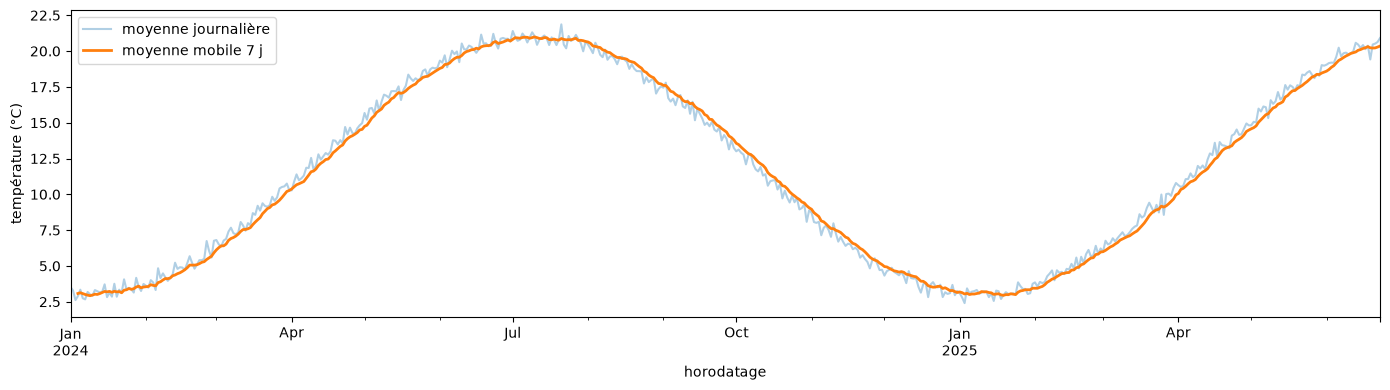

In [11]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(14, 4))
daily_temperature.plot(ax=ax, alpha=0.35, label='moyenne journalière')
(daily_temperature.rolling(7, min_periods=4).mean()
 .plot(ax=ax, linewidth=2, label='moyenne mobile 7 j'))
ax.set_ylabel('température (°C)')
ax.legend()
plt.tight_layout()
plt.show()

`min_periods=4` autorise le calcul dès le quatrième point disponible, au lieu d'attendre
sept valeurs complètes. Sans cela, chaque trou de la série efface les six points suivants
de la courbe lissée.

### Partie autonome

In [12]:
# Q4. Détecter automatiquement la panne du capteur CAP-B :
#     trouver les plages horaires sans aucune mesure de plus de 24 heures.
#     Indice : réindexer sur une plage horaire complète puis repérer les suites de NaN.

def find_outages(sensors, sensor_id, min_hours=24):
    """Renvoie les plages de plus de min_hours heures sans aucune mesure pour un capteur."""
    series = (sensors[sensors['id_capteur'] == sensor_id]
              .set_index('horodatage')
              .sort_index())

    # 1. Toutes les heures attendues entre la première et la dernière mesure
    full_range = pd.date_range(series.index.min(), series.index.max(), freq='h')

    # 2. True pour chaque heure absente des données
    missing = pd.Series(~full_range.isin(series.index), index=full_range)

    # 3. Numéroter les suites : le numéro change à chaque passage présent <-> absent
    run_id = (missing != missing.shift()).cumsum()

    rows = []
    for _, run in missing[missing].groupby(run_id[missing]):
        if len(run) > min_hours:
            rows.append({'debut': run.index.min(),
                         'fin': run.index.max(),
                         'heures_manquantes': len(run)})
    return pd.DataFrame(rows)


for sensor_id in ['CAP-A', 'CAP-B', 'CAP-C']:
    outages = find_outages(sensors, sensor_id)
    print(f'{sensor_id} : {len(outages)} panne(s) de plus de 24 h')
    if not outages.empty:
        print(outages.to_string(index=False))

CAP-A : 0 panne(s) de plus de 24 h
CAP-B : 1 panne(s) de plus de 24 h
     debut                 fin  heures_manquantes
2024-06-03 2024-06-13 23:00:00                264
CAP-C : 0 panne(s) de plus de 24 h


In [13]:
# Q5. Détecter le capteur bloqué : trouver la période où CAP-C renvoie une valeur
#     strictement constante pendant plus de 24 relevés consécutifs.
#     Un capteur bloqué ne produit pas de valeur manquante : c'est ce qui rend
#     cette anomalie difficile à repérer et coûteuse à laisser passer.

def find_stuck_periods(sensors, sensor_id, column='temperature_c', min_readings=24):
    """Renvoie les périodes où un capteur répète la même valeur plus de min_readings fois."""
    values = (sensors[sensors['id_capteur'] == sensor_id]
              .set_index('horodatage')
              .sort_index()[column]
              .dropna())

    # Le numéro change à chaque fois que la valeur change
    run_id = (values != values.shift()).cumsum()

    rows = []
    for _, run in values.groupby(run_id):
        if len(run) > min_readings:
            rows.append({'debut': run.index.min(),
                         'fin': run.index.max(),
                         'valeur': run.iloc[0],
                         'releves_identiques': len(run)})
    return pd.DataFrame(rows)


for sensor_id in ['CAP-A', 'CAP-B', 'CAP-C']:
    stuck = find_stuck_periods(sensors, sensor_id)
    print(f'{sensor_id} : {len(stuck)} période(s) bloquée(s)')
    if not stuck.empty:
        print(stuck.to_string(index=False))

CAP-A : 0 période(s) bloquée(s)
CAP-B : 0 période(s) bloquée(s)
CAP-C : 1 période(s) bloquée(s)
              debut                 fin  valeur  releves_identiques
2024-09-10 01:00:00 2024-09-14 23:00:00    17.4                 117


Semaines : 106 | Mois : 24
                      ca  nb_commandes  panier_moyen
date_commande                                       
2023-01-01      917922.0           739        1242.0
2023-02-01      839186.0           680        1234.0
2023-03-01      866081.0           724        1196.0
2023-04-01      908301.0           699        1299.0
2023-05-01      885169.0           716        1236.0
2023-06-01      891112.0           735        1212.0
2023-07-01      924955.0           750        1233.0
2023-08-01      623025.0           500        1246.0
2023-09-01      914175.0           745        1227.0
2023-10-01      879396.0           713        1233.0
2023-11-01     1142616.0           704        1623.0
2023-12-01     1165003.0           732        1592.0
2024-01-01      916318.0           733        1250.0
2024-02-01      859307.0           685        1254.0
2024-03-01      936314.0           724        1293.0
2024-04-01      931218.0           734        1269.0
2024-05-01      958

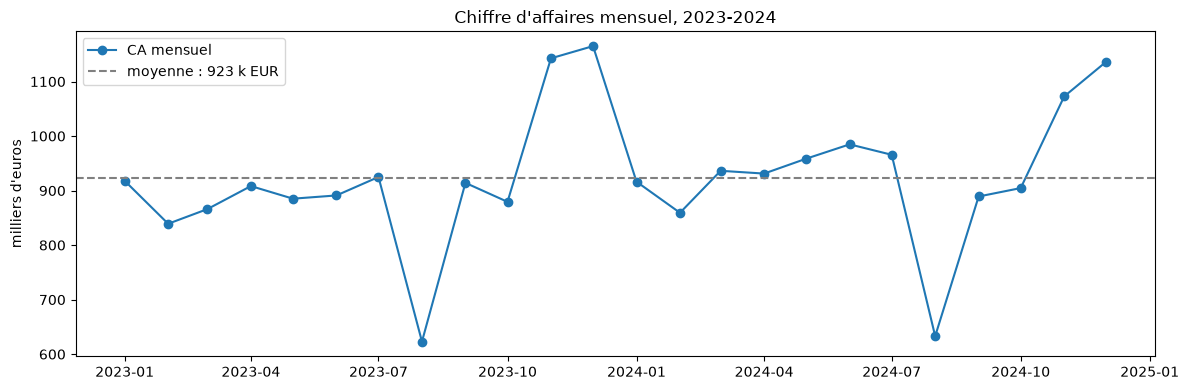

In [14]:
# Q6. Agréger les ventes par semaine puis par mois. Tracer la série mensuelle du
#     chiffre d'affaires et commenter la saisonnalité observée.

import matplotlib.pyplot as plt

sales_by_date = sales.set_index('date_commande').sort_index()

# Par semaine et par mois : chiffre d'affaires, nombre de commandes, panier moyen
weekly = sales_by_date['montant'].resample('W').agg(['sum', 'count'])
monthly = sales_by_date['montant'].resample('MS').agg(['sum', 'count', 'mean'])
monthly.columns = ['ca', 'nb_commandes', 'panier_moyen']

print('Semaines :', len(weekly), '| Mois :', len(monthly))
print(monthly.round(0))

monthly_average = monthly['ca'].mean()

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(monthly.index, monthly['ca'] / 1000, marker='o', label='CA mensuel')
ax.axhline(monthly_average / 1000, color='grey', linestyle='--',
           label=f'moyenne : {monthly_average / 1000:.0f} k EUR')
ax.set_title('Chiffre d\'affaires mensuel, 2023-2024')
ax.set_ylabel('milliers d\'euros')
ax.legend()
plt.tight_layout()
plt.show()

# Saisonnalité nette, identique sur les deux années :
# - pic en novembre et décembre (environ +20 à +25 % par rapport à la moyenne, 1,1 à 1,2 M EUR) ;
#   le nombre de commandes reste normal (environ 700), c'est le PANIER MOYEN qui grimpe
#   (environ 1 600 EUR contre 1 250 EUR) : les clients achètent plus d'articles en fin d'année ;
# - creux en août (environ -32 %, 620 k EUR) ; ici le panier moyen est normal, c'est le NOMBRE
#   de commandes qui chute (environ 500 contre 730) : il y a moins de clients pendant les congés ;
# - le reste de l'année est stable autour de 900 k EUR par mois.
# Les deux saisonnalités n'ont donc pas la même cause, ce qu'un graphique du seul CA ne montre pas.

In [15]:
save_dataset(sales, 'ventes_temporelles')

écrit : ventes_temporelles.parquet (16992, 38)


WindowsPath('c:/Users/yoanv/Desktop/Préparation et manipulation de données/projet 1/ateliers_PMD/data/processed/ventes_temporelles.parquet')

---
## Livrable de la séance

- la fonction `parse_dates` avec son rapport de conversion, dans `src/` ;
- le jeu de ventes enrichi de ses variables temporelles ;
- les deux fonctions de détection d'anomalies de capteur (panne et blocage) ;
- un graphique commenté de la saisonnalité mensuelle.